# Boréal Assurances : démonstration de la chaîne de données

Ce notebook présente le travail réalisé, couche par couche, avec les chiffres réels de l'entrepôt (lecture seule).

```
Sources (5)  ->  raw (brut)  ->  prep (préparation) + qualite  ->  core (étoile)  ->  marts  ->  dashboard (app.py)
                       orchestration : pipeline/run_all.py  |  déclenchement : pipeline/declencheur.py
```

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

racine = Path.cwd() if (Path.cwd() / "warehouse").exists() else Path.cwd().parent
con = duckdb.connect(str(racine / "warehouse" / "boreal.duckdb"), read_only=True)


def sql(requete):
    """Exécute une requête et renvoie le résultat sous forme de tableau."""
    return con.execute(requete).df()


def lignes_par_table(schema):
    """Nombre de lignes de chaque table d'un schéma."""
    tables = sql(f"select table_name from information_schema.tables where table_schema = '{schema}' order by 1")["table_name"]
    return pd.DataFrame({"table": [f"{schema}.{t}" for t in tables],
                         "lignes": [con.execute(f"select count(*) from {schema}.{t}").fetchone()[0] for t in tables]})

## 1. Couche brute (raw) : copie fidèle des 5 sources

Toutes les valeurs sont lues en texte, sans correction ; chaque ligne garde son fichier d'origine et sa date de chargement.

In [2]:
lignes_par_table("raw")

,table,lignes
0,raw.audits,372
1,raw.clients,15200
2,raw.contrats,20264
3,raw.reglements,3207
4,raw.sinistres,2805


In [3]:
# Journal d'ingestion : dernier chargement de chaque fichier
sql("""
select source, count(*) as fichiers, sum(lignes_lues) as lignes, min(statut) as statut
from (select * from meta.ingestion_log
      qualify row_number() over (partition by fichier order by charge_le desc) = 1)
group by 1 order by 1
""")

,source,fichiers,lignes,statut
0,raw.audits,1,372.0,OK
1,raw.clients,1,15200.0,OK
2,raw.contrats,1,20264.0,OK
3,raw.reglements,64,3207.0,OK
4,raw.sinistres,1,2805.0,OK


### Rejouer un mois ne crée aucun doublon

Le fichier d'un mois peut être rechargé autant de fois qu'on veut : le journal garde chaque chargement, mais le nombre de lignes
dans `raw.reglements` ne change pas.

In [4]:
sql("""
select fichier, lignes_lues, statut, charge_le
from meta.ingestion_log
where fichier like '%2024_03%'
order by charge_le
""")

,fichier,lignes_lues,statut,charge_le
0,reglements/reglements_2024_03.csv,86,OK,2026-10-19 12:17:13.010938
1,reglements/reglements_2024_03.csv,86,OK,2026-10-19 12:17:13.434315
2,reglements/reglements_2024_03.csv,86,OK,2026-10-19 12:31:19.062355
3,reglements/reglements_2024_03.csv,86,OK,2026-10-19 12:31:29.321327
4,reglements/reglements_2024_03.csv,86,OK,2026-10-19 12:31:31.269371
5,reglements/reglements_2024_03.csv,86,OK,2026-10-19 14:00:48.158865
6,reglements/reglements_2024_03.csv,86,OK,2026-10-19 14:01:00.791554
7,reglements/reglements_2024_03.csv,86,OK,2026-10-19 14:01:02.784420
8,reglements/reglements_2024_03.csv,86,OK,2026-10-22 14:34:00.690018
9,reglements/reglements_2024_03.csv,86,OK,2026-10-22 14:41:04.182337


## 2. Préparation et qualité : 23 règles, anomalies et quarantaine

Chaque règle a un traitement : **corriger**, **exclure** ou **signaler**. Les lignes corrigées ou exclues vont en quarantaine avec leur motif ; les lignes signalées restent dans les calculs.

In [5]:
sql("""
select traitement, count(*) as regles, sum(volume) as lignes_concernees
from qualite.registre
group by traitement
order by traitement
""")

,traitement,regles,lignes_concernees
0,Corriger,1,200.0
1,Exclure,11,83.0
2,Signaler,11,300.0


In [6]:
sql("select count(*) as lignes_en_quarantaine from qualite.quarantaine")

,lignes_en_quarantaine
0,283


In [7]:
# Les 5 règles qui concernent le plus de lignes
sql("""
select regle_id, categorie, description, gravite, traitement, volume
from qualite.registre
order by volume desc
limit 5
""")

,regle_id,categorie,description,gravite,traitement,volume
0,Q01,Complétude,Date de naissance absente,Mineure,Signaler,226
1,Q04,Unicité,Client en double (même email_hash) : on écarte...,Majeure,Corriger,200
2,Q07,Unicité,Paiement rejoué dans un fichier d'un autre moi...,Majeure,Exclure,32
3,Q19,Cohérence temporelle,Résiliation antérieure ou égale à la date d'ef...,Bloquante,Exclure,26
4,Q08,Validité,Prime annuelle nulle ou négative,Majeure,Exclure,25


## 3. Cœur (core) : modèle en étoile

Clients dédoublonnés, dimensions (contrat, client, date, garantie, segment de risque) et faits (exposition, sinistres, règlements).

In [8]:
lignes_par_table("core")

,table,lignes
0,core.dim_client,15000
1,core.dim_contrat,20264
2,core.dim_date,2008
3,core.dim_garantie,8
4,core.dim_segment_risque,30
5,core.fait_exposition,65103
6,core.fait_reglement,3175
7,core.fait_sinistre,2805
8,core.pont_client_survivant,15200


## 4. Tests automatisés : 19 tests, exécutés à chaque lancement

6 tests sur la couche brute et 13 sur la couche cœur (unicité des clés, intégrité entre tables, réconciliation des règlements, exposition toujours positive).
Un test en échec arrête la chaîne.

In [9]:
sql("""
select statut, count(*) as nb_tests
from marts.exploitation
where rubrique = 'TEST'
group by statut
""")

,statut,nb_tests
0,PASS,19


In [10]:
sql("select element as test from marts.exploitation where rubrique = 'TEST' order by 1")

,test
0,brut / test_reconciliation_lignes_brut_vs_sources
1,brut / test_rejeu_sans_doublon
2,brut / test_structure_des_montants_absorbee
3,brut / test_tous_les_fichiers_sont_journalises
4,brut / test_tracabilite_sur_chaque_ligne
5,brut / test_un_seul_jeu_de_lignes_par_fichier_...
6,coeur / test_aucun_client_en_double
7,coeur / test_cles_dimensions_uniques
8,coeur / test_cles_faits_uniques
9,coeur / test_contrats_actifs_tous_exposes


## 5. Marts : tables d'analyse pour le dashboard

In [11]:
lignes_par_table("marts")

,table,lignes
0,marts.base_technique,2544
1,marts.contributions_segments,108
2,marts.delais_sinistres,2800
3,marts.evolution_annuelle,6
4,marts.evolution_mensuelle,1980
5,marts.exploitation,47
6,marts.indicateurs,19
7,marts.retention_cohortes,30
8,marts.retention_multidetention,60
9,marts.valeur_client,14972


## 6. Exploitation : dernier chargement par source

In [12]:
sql("""
select element as source, detail as fichiers, valeur as lignes_chargees, statut
from marts.exploitation
where rubrique = 'CHARGEMENT'
order by 1
""")

,source,fichiers,lignes_chargees,statut
0,raw.audits,1 fichier(s),372.0,OK
1,raw.clients,1 fichier(s),15200.0,OK
2,raw.contrats,1 fichier(s),20264.0,OK
3,raw.reglements,64 fichier(s),3207.0,OK
4,raw.sinistres,1 fichier(s),2805.0,OK


## 7. Orchestration : une commande, des alertes, un déclencheur

| Ordre | Étape | Commande |
|---|---|---|
| 1 | Chargement des sources (brut) | `python pipeline/ingest.py` |
| 2 | Tests de la couche brute | `python tests/test_brut.py` |
| 3 | Préparation | `python pipeline/run_sql.py 02_prep` |
| 4 | Contrôles de qualité | `python pipeline/qualite.py` |
| 5 | Cœur | `python pipeline/run_sql.py 03_core` |
| 6 | Tests de la couche cœur | `python tests/test_coeur.py` |
| 7 | Marts | `python pipeline/run_sql.py 04_marts` |

- **Tout en une commande** : `python pipeline/run_all.py` (7 étapes, arrêt au premier test en échec, alerte dans `warehouse/alertes.log`).
- **Recharger un mois** : `python pipeline/run_all.py --mois 2025_07` (rejouable sans doublon).
- **Exécution déclenchée par l'arrivée d'un fichier** : `python pipeline/declencheur.py --une-fois`, planifié chaque jour à 6 h par le planificateur Windows.

## 8. Résultats : le ratio sinistres/primes

Principe : on additionne les totaux, puis on divise (jamais de moyenne de ratios).

In [13]:
sql("""
select round(sum(prime_acquise))                       as primes_acquises,
       round(sum(paye))                                as sinistres_payes,
       round(sum(paye) / sum(prime_acquise) * 100, 1)  as ratio_pct,
       round(sum(nb_sinistres) / sum(annees_police) * 100, 2) as frequence_pct,
       round(sum(paye) / sum(nb_sinistres))            as cout_moyen
from marts.base_technique
""")

,primes_acquises,sinistres_payes,ratio_pct,frequence_pct,cout_moyen
0,19983953.0,11216834.0,56.1,4.33,5735.0


In [14]:
# Un seul dossier de 2,5 M€ explique le mauvais ratio de la zone 4
sql("""
select zone_risque,
       round(sum(paye) / sum(prime_acquise) * 100, 1)                     as ratio_pct,
       round(sum(paye - paye_exceptionnel) / sum(prime_acquise) * 100, 1) as ratio_hors_exceptionnel_pct
from marts.evolution_mensuelle
group by zone_risque
order by zone_risque
""")

,zone_risque,ratio_pct,ratio_hors_exceptionnel_pct
0,1,43.4,43.4
1,2,43.5,43.5
2,3,46.8,46.8
3,4,94.9,37.3
4,5,49.7,49.7


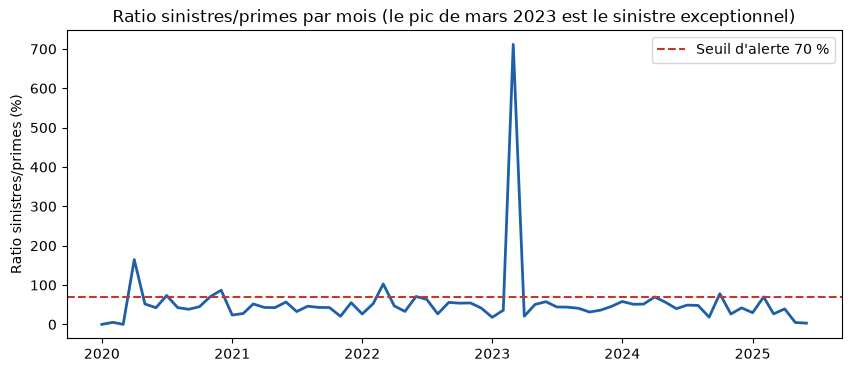

In [15]:
mensuel = sql("select mois, sum(paye) / sum(prime_acquise) as ratio from marts.evolution_mensuelle group by mois order by mois")
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(mensuel["mois"], mensuel["ratio"] * 100, color="#1f5fa8", linewidth=2)
ax.axhline(70, color="#c0392b", linestyle="--", label="Seuil d'alerte 70 %")
ax.set_ylabel("Ratio sinistres/primes (%)")
ax.set_title("Ratio sinistres/primes par mois (le pic de mars 2023 est le sinistre exceptionnel)")
ax.legend()
plt.show()

## Dashboard

`streamlit run app.py` : trois pages (Portefeuille, Technique et clients, Exploitation) et une page de définitions, alimentées uniquement par les marts.